# 03 No-show model
**All data is synthetic.** Logic lives in `src/model.py`; this notebook only reads the saved results (so the test set is not re-run). Rules: `docs/leakage_audit.md`, A43-A50.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200)
import json
from src.config import RESULTS, FIGURES
m = json.load(open(RESULTS / 'model_metrics.json'))

## Promotion decision (rule fixed before running)

In [2]:
pd.Series(m['promotion']).to_frame('value')

,value
val_pr_auc_M0,0.216526
val_pr_auc_M1,0.378666
val_pr_auc_M2,0.385796
gain_M2_minus_M1,0.007131
ci95_low,-0.00015
ci95_high,0.013441
rule,promote M2 if gain >= 0.02 and CI lower bound > 0
promote_M2,False
final_model,M1


## Test metrics

In [3]:
pd.read_csv(RESULTS / 'model_test_metrics.csv').round(4)

,model,final,pr_auc,roc_auc,brier,pr_auc_ci_low,pr_auc_ci_high,precision_at_20pct,recall_at_20pct,lift_at_20pct
0,M0,False,0.2225,0.5000,0.1730,0.2178,0.2275,NaN,NaN,NaN
1,M1,True,0.3871,0.6714,0.1603,0.3739,0.4008,0.4002,0.3597,1.7984
2,M2,False,0.3952,0.6707,0.1597,0.3829,0.4095,0.4057,0.3646,1.8228


## Calibration, cumulative gain, precision-recall

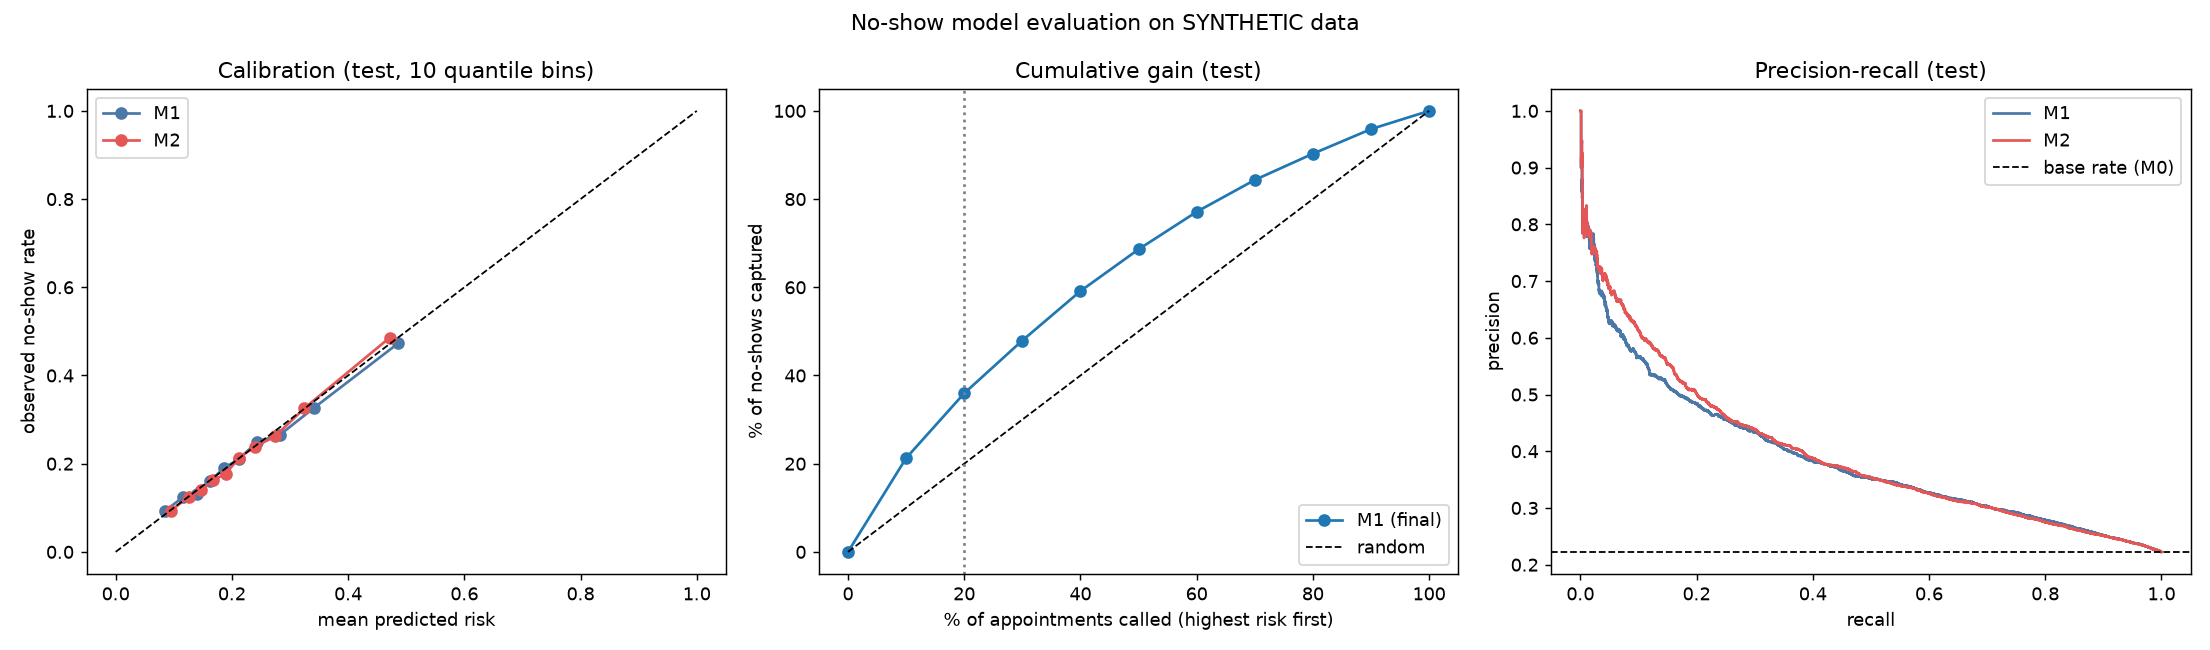

In [4]:
Image(filename=str(FIGURES / 'model_eval.png'))

## Lift by decile

In [5]:
t = pd.read_csv(RESULTS / 'lift_table.csv'); t[t.is_final].round(3)

,model,decile,n,no_shows,no_show_rate,lift,cum_capture,cum_lift,is_final
0,M1,1,3122,1477,0.473,2.126,0.213,2.126,True
1,M1,2,3122,1022,0.327,1.471,0.360,1.798,True
2,M1,3,3122,831,0.266,1.196,0.479,1.598,True
3,M1,4,3122,779,0.250,1.121,0.591,1.478,True
4,M1,5,3122,658,0.211,0.947,0.686,1.372,True
5,M1,6,3122,591,0.189,0.851,0.771,1.285,True
6,M1,7,3122,502,0.161,0.723,0.843,1.205,True
7,M1,8,3122,413,0.132,0.594,0.903,1.129,True
8,M1,9,3122,388,0.124,0.558,0.959,1.065,True
9,M1,10,3122,287,0.092,0.413,1.000,1.000,True


## SHAP importance

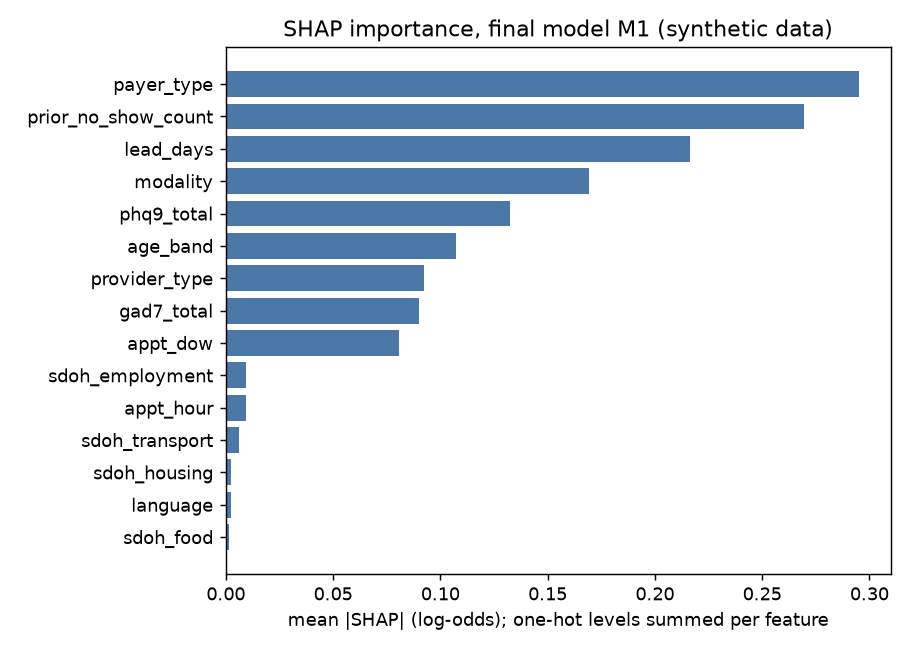

In [6]:
Image(filename=str(FIGURES / 'shap_importance.png'))

## Fairness slices

In [7]:
display(pd.read_csv(RESULTS / 'fairness_slices.csv').round(3)); pd.read_csv(RESULTS / 'fairness_tests.csv').round(4)

,variable,level,n,no_show_rate,flag_rate,precision_flagged,false_negative_rate,false_positive_rate
0,payer_type,Commercial,11782,0.173,0.082,0.353,0.832,0.064
1,payer_type,Medicaid,11118,0.282,0.349,0.423,0.477,0.280
2,payer_type,Medicare,3790,0.192,0.106,0.360,0.802,0.084
3,payer_type,Self-pay,3899,0.233,0.221,0.371,0.648,0.182
4,payer_type,Unknown,631,0.214,0.211,0.383,0.622,0.165
5,age_band,18-24,5533,0.274,0.279,0.423,0.569,0.221
6,age_band,25-34,8408,0.230,0.233,0.404,0.590,0.181
7,age_band,35-49,8723,0.210,0.178,0.381,0.676,0.140
8,age_band,50-64,6075,0.203,0.149,0.384,0.719,0.115
9,age_band,65+,2481,0.177,0.114,0.410,0.736,0.082


,variable,error_rate,chi2,p_raw,p_holm
0,payer_type,false-negative rate,773.6217,0.0,0.0
1,payer_type,false-positive rate,1710.3541,0.0,0.0
2,age_band,false-negative rate,115.0696,0.0,0.0
3,age_band,false-positive rate,324.2348,0.0,0.0


## Outreach simulation (assumptions A49)

In [8]:
pd.DataFrame(m['simulation']['rows']).round(2)

,scenario,prevented,prevented_low,prevented_high,per_1000_resolved,calls_per_prevented
0,"A: uniform absolute reduction, model top 20%",208.92,148.24,269.60,6.69,29.89
1,"A: uniform absolute reduction, random 20%",208.92,148.24,269.60,6.69,29.89
2,"B: relative reduction, model top 20%",380.63,276.20,480.16,12.19,16.40
3,"B: relative reduction, random 20%",211.65,153.58,267.00,6.78,29.50
